# 07. Statistical Analysis

**RQ1.** How does English usage in K-pop lyrics differ across generations, based on artists' debut year?
**RQ2.** How has English usage in K-pop lyrics changed between 2000 and 2023, based on song release year?

Both questions are examined from four perspectives:

| Perspective | Main feature(s) | Supplementary |
|---|---|---|
| English frequency | `en_ratio` | — |
| Phrase length | `phrase_len_mean` | `phrase_len_max` |
| Lexical diversity | `mtld`, `ttr` | — |
| Korean–English code-switching | `cs_per100` (within lines), `cs_inter_per100` (at line breaks) | `cs_total_per100`, `mixed_line_ratio` |

1. Setup
2. Descriptive Statistics
   - 2.1 By Generation
   - 2.2 By Release Period
   - 2.3 Figures
3. RQ1-a: Generational Differences (all RQ1 songs)
   - 3.1 Kruskal–Wallis
   - 3.2 Pairwise Comparisons (Dunn)
   - 3.3 Median Confidence Intervals
   - 3.4 Two-Part View of English Frequency
4. RQ1-b: Controlling for Release Period
   - 4.1 Within-Period Comparison (2015–2023)
   - 4.2 Regression with Release Year
   - 4.3 Comparison of the Three Approaches
5. RQ2: Temporal Trends (2000–2023)
   - 5.1 Yearly Values
   - 5.2 Trend Tests (Mann–Kendall, Sen's slope)
   - 5.3 Song-Level Correlation
   - 5.4 Period Comparison (non-monotonic change)
6. Robustness Checks
   - 6.1 RQ1
   - 6.2 RQ2
7. Summary and Export

## 1. Setup

### Objective
Load the feature table (`06`) and define the analysis settings used in every section.

### Settings
- **Main version:** `_all` (fillers included); `_nofill` is used in the robustness checks (6).
- **Multiple testing:** p-values are Holm-corrected across the six main features within each analysis.
- **Lexical diversity:** only songs with at least `MIN_EN_TOKENS` English tokens.
- **Required packages:** `scipy`, `statsmodels`, `scikit-posthocs`, `pymannkendall`, `matplotlib`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import scikit_posthocs as sp
import pymannkendall as mk

INTERIM_DIR = Path("../data/interim")
TABLE_DIR = Path("../results/tables")
FIG_DIR = Path("../results/figures")
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_pickle(INTERIM_DIR / "features.pkl")
print(f"Songs: {len(df):,}")

Songs: 7,984


In [2]:
PERSPECTIVES = {
    "English frequency": ["en_ratio"],
    "Phrase length": ["phrase_len_mean"],
    "Lexical diversity": ["mtld", "ttr"],
    "Code-switching": ["cs_per100", "cs_inter_per100"],
}
SUPPLEMENTARY = ["phrase_len_max", "cs_total_per100", "mixed_line_ratio"]

LABELS = {
    "en_ratio": "English ratio",
    "phrase_len_mean": "Mean phrase length",
    "phrase_len_max": "Longest phrase",
    "mtld": "MTLD",
    "ttr": "TTR",
    "cs_per100": "Switches within lines /100 tokens",
    "cs_inter_per100": "Switches at line breaks /100 tokens",
    "cs_total_per100": "All switches /100 tokens",
    "mixed_line_ratio": "Mixed-line ratio",
}

MAIN_FEATURES = [f for fs in PERSPECTIVES.values() for f in fs]
PERSPECTIVE_OF = {f: p for p, fs in PERSPECTIVES.items() for f in fs}

VERSION = "all"
MIN_EN_TOKENS = 50
GENS = ["1st", "2nd", "3rd", "4th"]
GEN_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # ordinal blue ramp, light → dark
WITHIN_PERIOD = (2015, 2023)
N_BOOT = 2000
rng = np.random.default_rng(0)


def values(data, feature, version=VERSION, min_en=MIN_EN_TOKENS):
    """Feature values for the given version; TTR/MTLD are masked below min_en English tokens."""
    if feature in ("ttr", "mtld"):
        return data[f"{feature}_raw_{version}"].where(data[f"n_en_{version}"] >= min_en).astype(float)
    return data[f"{feature}_{version}"].astype(float)


def rq1_songs(data, gen_col="gen_baseline", high_conf_only=False):
    """RQ1 songs with a 1st–4th generation label under the given scheme."""
    out = data[data["in_rq1"] & data[gen_col].astype("string").isin(GENS)].copy()
    if high_conf_only:
        out = out[out["high_conf"]]
    out["gen"] = pd.Categorical(out[gen_col].astype(str), categories=GENS, ordered=True)
    out["gen_rank"] = out["gen"].cat.codes + 1
    return out


def holm(p):
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out


rq1 = rq1_songs(df)
rq2 = df[df["in_rq2"]].copy()
rq2["release_year"] = rq2["release_year"].astype(int)

# Korean artists only: excludes foreign artists and unidentified artists (used in 5.4 and 6.2)
KOREAN_TYPES = ["eligible", "korean_not_eligible"]
rq2_korean = rq2[rq2["type_group"].isin(KOREAN_TYPES)].copy()

print(f"RQ1 songs: {len(rq1):,}")
display(rq1["gen"].value_counts().reindex(GENS).rename("songs").to_frame())
print(f"RQ2 songs: {len(rq2):,} (release years {rq2['release_year'].min()}–{rq2['release_year'].max()})")
print(f"RQ2 songs by Korean artists: {len(rq2_korean):,} "
      f"(excluded: {(rq2['type_group'] == 'foreign').sum():,} foreign, {(rq2['type_group'] == 'unknown').sum():,} unknown)")

RQ1 songs: 5,928


,songs
gen,
1st,1818
2nd,2736
3rd,1226
4th,148


RQ2 songs: 7,871 (release years 2000–2023)
RQ2 songs by Korean artists: 7,103 (excluded: 140 foreign, 628 unknown)


## 2. Descriptive Statistics

### Objective
Describe each feature by generation and by release period before testing.

### Procedure
- Median and interquartile range (IQR), since most features are skewed.
- Share of songs with a value above 0, since English frequency and code-switching are 0 for many songs.
- `n` differs by feature: lexical diversity covers only songs with enough English tokens, and phrase length only songs with English.

### 2.1 By Generation

In [3]:
def describe_by(data, group, features):
    rows = []
    for f in features:
        v = values(data, f)
        for g, x in v.groupby(group, observed=True):
            x = x.dropna()
            rows.append({
                "perspective": PERSPECTIVE_OF.get(f, "supplementary"), "feature": f, "group": g,
                "n": len(x), "median": x.median(), "q1": x.quantile(.25), "q3": x.quantile(.75),
                "mean": x.mean(), "pct_above_0": (x > 0).mean() * 100,
            })
    return pd.DataFrame(rows)

def fmt_median_iqr(d):
    digits = d["median"].abs().max() < 1 and 3 or 2
    return d.apply(lambda r: f"{r['median']:.{digits}f} [{r['q1']:.{digits}f}–{r['q3']:.{digits}f}]", axis=1)

desc_gen = describe_by(rq1, rq1["gen"], MAIN_FEATURES + SUPPLEMENTARY)

wide = (desc_gen.assign(cell=desc_gen.groupby("feature", group_keys=False).apply(fmt_median_iqr))
        .pivot(index=["perspective", "feature"], columns="group", values="cell")[GENS])
print("Median [IQR] by generation:")
display(wide.loc[[(PERSPECTIVE_OF.get(f, "supplementary"), f) for f in MAIN_FEATURES + SUPPLEMENTARY]])

print("Songs with a value (n) and share of songs above 0 (%):")
display(desc_gen.pivot(index="feature", columns="group", values="n")[GENS].loc[MAIN_FEATURES + SUPPLEMENTARY])
display(desc_gen.pivot(index="feature", columns="group", values="pct_above_0")[GENS]
        .loc[["en_ratio", "cs_per100", "cs_inter_per100", "cs_total_per100"]].round(1))

Median [IQR] by generation:


group                                               1st                  2nd  \
perspective       feature                                                      
English frequency en_ratio          0.000 [0.000–0.203]  0.070 [0.000–0.293]   
Phrase length     phrase_len_mean      3.59 [2.50–4.39]     3.58 [2.73–4.33]   
Lexical diversity mtld               14.40 [8.69–24.44]    9.50 [6.26–15.69]   
                  ttr               0.293 [0.194–0.423]  0.256 [0.165–0.363]   
Code-switching    cs_per100            0.00 [0.00–1.36]     0.00 [0.00–2.48]   
                  cs_inter_per100      0.00 [0.00–4.31]     2.21 [0.00–6.54]   
supplementary     phrase_len_max       6.00 [4.00–7.00]     6.00 [4.00–7.00]   
                  cs_total_per100      0.00 [0.00–6.35]     3.21 [0.00–9.25]   
                  mixed_line_ratio  0.000 [0.000–0.048]  0.000 [0.000–0.091]   

group                                               3rd                  4th  
perspective       feature                                                     
English frequency en_ratio          0.181 [0.000–0.382]  0.471 [0.215–0.613]  
Phrase length     phrase_len_mean      3.42 [2.70–4.21]     3.56 [2.92–4.25]  
Lexical diversity mtld               10.64 [6.74–17.05]   12.88 [8.43–18.69]  
                  ttr               0.272 [0.184–0.367]  0.308 [0.227–0.370]  
Code-switching    cs_per100            0.97 [0.00–3.69]     3.67 [0.93–6.82]  
                  cs_inter_per100      4.67 [0.00–8.08]     7.50 [3.57–9.67]  
supplementary     phrase_len_max       6.00 [5.00–8.00]     7.00 [6.00–8.00]  
                  cs_total_per100     6.60 [0.00–11.69]   11.55 [5.90–16.62]  
                  mixed_line_ratio  0.036 [0.000–0.136]  0.128 [0.031–0.242]

Songs with a value (n) and share of songs above 0 (%):


group,1st,2nd,3rd,4th
feature,,,,
en_ratio,1818,2736,1226,148
phrase_len_mean,907,1682,916,132
mtld,407,904,553,109
ttr,407,904,553,109
cs_per100,1818,2736,1226,148
cs_inter_per100,1818,2736,1226,148
phrase_len_max,907,1682,916,132
cs_total_per100,1818,2736,1226,148
mixed_line_ratio,1818,2736,1226,148


group,1st,2nd,3rd,4th
feature,,,,
en_ratio,49.9,61.5,74.7,89.2
cs_per100,36.4,48.4,59.7,81.8
cs_inter_per100,48.4,60.1,72.4,85.8
cs_total_per100,49.0,60.8,72.8,85.8


### 2.2 By Release Period

In [4]:
PERIOD_BINS = [1999, 2004, 2009, 2014, 2019, 2023]
PERIOD_LABELS = ["2000–04", "2005–09", "2010–14", "2015–19", "2020–23"]
rq2["period"] = pd.cut(rq2["release_year"], bins=PERIOD_BINS, labels=PERIOD_LABELS)

desc_period = describe_by(rq2, rq2["period"], MAIN_FEATURES + SUPPLEMENTARY)
wide_p = (desc_period.assign(cell=desc_period.groupby("feature", group_keys=False).apply(fmt_median_iqr))
          .pivot(index=["perspective", "feature"], columns="group", values="cell")[PERIOD_LABELS])
print("Median [IQR] by release period:")
display(wide_p.loc[[(PERSPECTIVE_OF.get(f, "supplementary"), f) for f in MAIN_FEATURES + SUPPLEMENTARY]])

print("Share of songs above 0 (%):")
display(desc_period.pivot(index="feature", columns="group", values="pct_above_0")[PERIOD_LABELS]
        .loc[["en_ratio", "cs_per100", "cs_inter_per100", "cs_total_per100"]].round(1))

Median [IQR] by release period:


group                                           2000–04              2005–09  \
perspective       feature                                                      
English frequency en_ratio          0.000 [0.000–0.200]  0.001 [0.000–0.221]   
Phrase length     phrase_len_mean      3.75 [2.67–4.67]     3.67 [2.73–4.50]   
Lexical diversity mtld              19.99 [11.79–31.87]   12.80 [7.95–22.56]   
                  ttr               0.321 [0.232–0.429]  0.279 [0.180–0.390]   
Code-switching    cs_per100         0.000 [0.000–0.917]  0.000 [0.000–1.476]   
                  cs_inter_per100      0.00 [0.00–3.32]     0.00 [0.00–4.39]   
supplementary     phrase_len_max       6.00 [4.00–7.75]     6.00 [4.00–7.00]   
                  cs_total_per100      0.00 [0.00–5.08]     0.00 [0.00–6.40]   
                  mixed_line_ratio  0.000 [0.000–0.037]  0.000 [0.000–0.054]   

group                                           2010–14              2015–19  \
perspective       feature                                                      
English frequency en_ratio          0.062 [0.000–0.302]  0.138 [0.000–0.326]   
Phrase length     phrase_len_mean      3.56 [2.67–4.40]     3.39 [2.63–4.13]   
Lexical diversity mtld                9.09 [6.21–14.98]   10.20 [6.46–16.20]   
                  ttr               0.241 [0.161–0.338]  0.266 [0.176–0.370]   
Code-switching    cs_per100         0.000 [0.000–2.033]  0.775 [0.000–3.333]   
                  cs_inter_per100      1.62 [0.00–6.36]     4.00 [0.00–7.51]   
supplementary     phrase_len_max       6.00 [4.00–7.00]     6.00 [5.00–7.00]   
                  cs_total_per100      2.49 [0.00–8.90]    5.64 [0.00–10.93]   
                  mixed_line_ratio  0.000 [0.000–0.072]  0.026 [0.000–0.117]   

group                                           2020–23  
perspective       feature                                
English frequency en_ratio          0.141 [0.000–0.469]  
Phrase length     phrase_len_mean      3.64 [2.89–4.40]  
Lexical diversity mtld              15.31 [10.40–26.56]  
                  ttr               0.312 [0.248–0.407]  
Code-switching    cs_per100         0.612 [0.000–3.968]  
                  cs_inter_per100      2.46 [0.00–7.55]  
supplementary     phrase_len_max       7.00 [5.00–8.00]  
                  cs_total_per100     4.02 [0.00–11.43]  
                  mixed_line_ratio  0.023 [0.000–0.145]

Share of songs above 0 (%):


group,2000–04,2005–09,2010–14,2015–19,2020–23
feature,,,,,
en_ratio,48.9,50.0,60.6,71.2,64.6
cs_per100,32.1,36.7,44.8,56.9,53.3
cs_inter_per100,44.7,46.2,57.0,69.7,60.0
cs_total_per100,45.4,46.9,57.8,70.2,60.2


### 2.3 Figures

Box plots of the six main features by generation. Outliers beyond the whiskers are hidden to keep the boxes readable (e.g. the 370-token phrase); they remain in all tests.

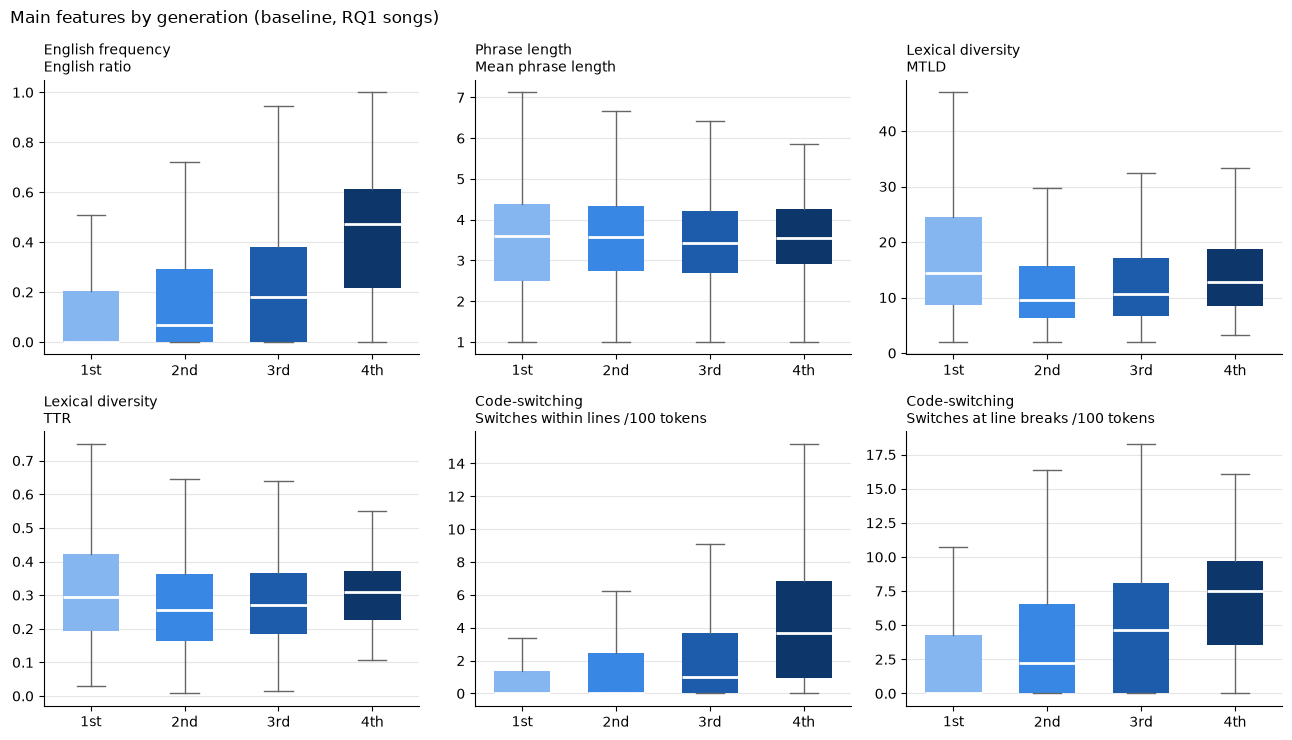

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, f in zip(axes.flat, MAIN_FEATURES):
    v = values(rq1, f)
    data = [v[rq1["gen"] == g].dropna() for g in GENS]
    bp = ax.boxplot(data, tick_labels=GENS, showfliers=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color="white", linewidth=2), whiskerprops=dict(color="#666"),
                    capprops=dict(color="#666"), boxprops=dict(linewidth=0))
    for patch, c in zip(bp["boxes"], GEN_COLORS):
        patch.set_facecolor(c)
    ax.set_title(f"{PERSPECTIVE_OF[f]}\n{LABELS[f]}", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Main features by generation (baseline, RQ1 songs)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_boxplots_by_generation.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. RQ1-a: Generational Differences (all RQ1 songs)

### Objective
Test whether each feature differs across the four generations (baseline scheme, all RQ1 songs).

### 3.1 Kruskal–Wallis

#### Procedure
- Kruskal–Wallis test per feature (non-parametric; the features are skewed and zero-heavy).
- Effect size ε² = H / (n − 1). Rough guide: 0.01 small, 0.08 medium, 0.26 large.
- Direction: Spearman ρ between generation order (1st = 1 … 4th = 4) and the feature. ρ > 0 means higher values in later generations.
- p-values Holm-corrected across the six features.

In [6]:
def kruskal_by_gen(data, feature, **kw):
    v = values(data, feature, **kw)
    ok = v.notna()
    groups = [v[ok & (data["gen"] == g)] for g in GENS]
    n = int(ok.sum())
    res = {"perspective": PERSPECTIVE_OF.get(feature, "supplementary"), "feature": feature, "n": n}
    res.update({f"n_{g}": len(x) for g, x in zip(GENS, groups)})
    res.update({f"median_{g}": x.median() for g, x in zip(GENS, groups)})
    try:
        H, p = stats.kruskal(*[x for x in groups if len(x) > 0])
    except ValueError:            # all values identical
        H, p = 0.0, 1.0
    res.update({"H": H, "p": p, "epsilon2": H / (n - 1) if n > 1 else np.nan,
                "rho": stats.spearmanr(data.loc[ok, "gen_rank"], v[ok]).statistic})
    return res

def kruskal_table(data, features=MAIN_FEATURES, **kw):
    t = pd.DataFrame([kruskal_by_gen(data, f, **kw) for f in features])
    t["p_holm"] = holm(t["p"]).values
    return t

kw_all = kruskal_table(rq1)
cols = ["perspective", "feature", "n"] + [f"median_{g}" for g in GENS] + ["H", "epsilon2", "rho", "p_holm"]
display(kw_all[cols].round(4))

,perspective,feature,n,median_1st,median_2nd,median_3rd,median_4th,H,epsilon2,rho,p_holm
0,English frequency,en_ratio,5928,0.0000,0.0695,0.1809,0.4708,373.1253,0.0630,0.2329,0.0000
1,Phrase length,phrase_len_mean,3637,3.5909,3.5792,3.4170,3.5602,3.5220,0.0010,-0.0112,0.3179
2,Lexical diversity,mtld,1973,14.4000,9.5041,10.6393,12.8829,81.1470,0.0411,-0.0803,0.0000
3,Lexical diversity,ttr,1973,0.2931,0.2561,0.2717,0.3081,25.7880,0.0131,-0.0244,0.0000
4,Code-switching,cs_per100,5928,0.0000,0.0000,0.9733,3.6713,295.7442,0.0499,0.2078,0.0000
5,Code-switching,cs_inter_per100,5928,0.0000,2.2099,4.6662,7.5048,347.5164,0.0586,0.2351,0.0000


### 3.2 Pairwise Comparisons (Dunn)

#### Procedure
- Dunn's test for all six generation pairs, Holm-corrected within each feature.
- Effect size: Cliff's δ (later generation vs. earlier). δ > 0 means the later generation has higher values. Rough guide: |δ| 0.15 small, 0.33 medium, 0.47 large.

In [7]:
PAIRS = [(a, b) for i, a in enumerate(GENS) for b in GENS[i + 1:]]

def cliffs_delta(x, y):
    """P(x > y) − P(x < y)"""
    if len(x) == 0 or len(y) == 0:
        return np.nan
    u = stats.mannwhitneyu(x, y).statistic
    return 2 * u / (len(x) * len(y)) - 1

def dunn_table(data, features=MAIN_FEATURES, **kw):
    rows = []
    for f in features:
        v = values(data, f, **kw)
        d = pd.DataFrame({"v": v, "gen": data["gen"].astype(str)}).dropna()
        pmat = sp.posthoc_dunn(d, val_col="v", group_col="gen", p_adjust="holm")
        for a, b in PAIRS:
            xa, xb = d.loc[d["gen"] == a, "v"], d.loc[d["gen"] == b, "v"]
            rows.append({"perspective": PERSPECTIVE_OF[f], "feature": f, "pair": f"{a} vs {b}",
                         "median_a": xa.median(), "median_b": xb.median(),
                         "cliffs_delta": cliffs_delta(xb, xa),
                         "p_holm": pmat.loc[a, b] if a in pmat.index and b in pmat.columns else np.nan})
    return pd.DataFrame(rows)

dunn_all = dunn_table(rq1)

print("Cliff's δ (later vs. earlier generation; * p_holm < .05):")
cell = dunn_all.apply(lambda r: f"{r['cliffs_delta']:+.2f}{'*' if r['p_holm'] < .05 else ''}", axis=1)
display(dunn_all.assign(cell=cell).pivot(index="feature", columns="pair", values="cell")
        .loc[MAIN_FEATURES, [f"{a} vs {b}" for a, b in PAIRS]])

Cliff's δ (later vs. earlier generation; * p_holm < .05):


pair,1st vs 2nd,1st vs 3rd,1st vs 4th,2nd vs 3rd,2nd vs 4th,3rd vs 4th
feature,,,,,,
en_ratio,+0.14*,+0.32*,+0.64*,+0.18*,+0.55*,+0.43*
phrase_len_mean,+0.01,-0.02,+0.03,-0.04,+0.02,+0.07
mtld,-0.29*,-0.23*,-0.09,+0.07,+0.24*,+0.16*
ttr,-0.15*,-0.11*,-0.02,+0.06,+0.18*,+0.12
cs_per100,+0.13*,+0.26*,+0.56*,+0.14*,+0.47*,+0.34*
cs_inter_per100,+0.16*,+0.33*,+0.56*,+0.18*,+0.43*,+0.26*


### 3.3 Median Confidence Intervals

#### Procedure
- Bootstrap 95% confidence interval of each generation's median (`N_BOOT` resamples).
- Especially relevant for the small 4th generation, where intervals are wider.

In [8]:
def boot_median_ci(x, n_boot=N_BOOT):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return np.nan, np.nan
    meds = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])

rows = []
for f in MAIN_FEATURES:
    v = values(rq1, f)
    for g in GENS:
        x = v[rq1["gen"] == g].dropna()
        lo, hi = boot_median_ci(x)
        rows.append({"feature": f, "gen": g, "n": len(x), "median": x.median(), "ci_low": lo, "ci_high": hi})
median_ci = pd.DataFrame(rows)

cell = median_ci.apply(lambda r: f"{r['median']:.3f} ({r['ci_low']:.3f}–{r['ci_high']:.3f})", axis=1)
display(median_ci.assign(cell=cell).pivot(index="feature", columns="gen", values="cell").loc[MAIN_FEATURES, GENS])

gen,1st,2nd,3rd,4th
feature,,,,
en_ratio,0.000 (0.000–0.011),0.070 (0.057–0.084),0.181 (0.157–0.208),0.471 (0.403–0.515)
phrase_len_mean,3.591 (3.462–3.680),3.579 (3.500–3.632),3.417 (3.333–3.500),3.560 (3.341–3.783)
mtld,14.400 (12.800–15.273),9.504 (8.945–10.008),10.639 (9.856–11.611),12.883 (11.340–15.000)
ttr,0.293 (0.267–0.315),0.256 (0.241–0.267),0.272 (0.256–0.282),0.308 (0.286–0.322)
cs_per100,0.000 (0.000–0.000),0.000 (0.000–0.282),0.973 (0.707–1.225),3.671 (2.600–4.733)
cs_inter_per100,0.000 (0.000–0.411),2.210 (1.821–2.516),4.666 (4.167–5.056),7.505 (6.269–8.422)


### 3.4 Two-Part View of English Frequency

#### Objective
`en_ratio` is 0 for many songs, so a single comparison mixes two questions. This section separates them:
- **(a) Use:** share of songs that contain any English (chi-square test, Cramér's V).
- **(b) Amount:** `en_ratio` among songs that contain English (Kruskal–Wallis).

In [9]:
has_en = rq1[f"n_en_{VERSION}"] > 0
ct = pd.crosstab(rq1["gen"], has_en).reindex(columns=[False, True], fill_value=0)
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

print("(a) Songs containing English")
display(pd.DataFrame({"songs": ct.sum(axis=1), "with English": ct[True],
                      "share (%)": (ct[True] / ct.sum(axis=1) * 100).round(1)}))
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p_chi:.4g}, Cramér's V = {cramers_v:.3f}")

print("\n(b) en_ratio among songs containing English")
two_part_b = kruskal_by_gen(rq1[has_en], "en_ratio")
display(pd.Series(two_part_b)[["n"] + [f"median_{g}" for g in GENS] + ["H", "p", "epsilon2", "rho"]].to_frame("value"))

(a) Songs containing English


,songs,with English,share (%)
gen,,,
1st,1818,907,49.9
2nd,2736,1682,61.5
3rd,1226,916,74.7
4th,148,132,89.2


chi2 = 241.44, df = 3, p = 4.643e-52, Cramér's V = 0.202

(b) en_ratio among songs containing English


,value
n,3637
median_1st,0.204
median_2nd,0.232127
median_3rd,0.286264
median_4th,0.504318
H,138.364448
p,0.0
epsilon2,0.038054
rho,0.160285


## 4. RQ1-b: Controlling for Release Period

### Objective
Generation and release period overlap strongly (the 3rd and 4th generations have almost no songs before 2010). This section checks whether the generational differences in 3 remain when release period is held constant, using two approaches.

### 4.1 Within-Period Comparison (2015–2023)

#### Procedure
- Keep only songs released in 2015–2023, the period in which all four generations are present.
- Repeat the Kruskal–Wallis test (3.1) and Dunn's test (3.2).

In [10]:
within = rq1[rq1["release_year"].between(*WITHIN_PERIOD)].copy()
print(f"Songs released {WITHIN_PERIOD[0]}–{WITHIN_PERIOD[1]}: {len(within):,}")
display(within["gen"].value_counts().reindex(GENS).rename("songs").to_frame())

kw_within = kruskal_table(within)
display(kw_within[cols].round(4))

dunn_within = dunn_table(within)
cell = dunn_within.apply(lambda r: f"{r['cliffs_delta']:+.2f}{'*' if r['p_holm'] < .05 else ''}", axis=1)
print("Cliff's δ within the period (* p_holm < .05):")
display(dunn_within.assign(cell=cell).pivot(index="feature", columns="pair", values="cell")
        .loc[MAIN_FEATURES, [f"{a} vs {b}" for a, b in PAIRS]])

Songs released 2015–2023: 1,881


,songs
gen,
1st,153
2nd,600
3rd,981
4th,147


,perspective,feature,n,median_1st,median_2nd,median_3rd,median_4th,H,epsilon2,rho,p_holm
0,English frequency,en_ratio,1881,0.0222,0.0661,0.2043,0.4634,183.3410,0.0975,0.2991,0.0000
1,Phrase length,phrase_len_mean,1320,3.8485,3.4310,3.4194,3.5490,4.1550,0.0032,-0.0053,0.2452
2,Lexical diversity,mtld,791,9.9217,12.8778,11.3626,12.7169,8.0303,0.0102,-0.0058,0.0908
3,Lexical diversity,ttr,791,0.2378,0.3036,0.2740,0.3070,10.0351,0.0127,-0.0093,0.0548
4,Code-switching,cs_per100,1881,0.0000,0.0000,1.2821,3.7415,130.2829,0.0693,0.2516,0.0000
5,Code-switching,cs_inter_per100,1881,0.9756,2.2148,4.9020,7.6305,107.6953,0.0573,0.2354,0.0000


Cliff's δ within the period (* p_holm < .05):


pair,1st vs 2nd,1st vs 3rd,1st vs 4th,2nd vs 3rd,2nd vs 4th,3rd vs 4th
feature,,,,,,
en_ratio,+0.09,+0.32*,+0.63*,+0.24*,+0.58*,+0.41*
phrase_len_mean,-0.12,-0.12,-0.08,+0.00,+0.06,+0.06
mtld,+0.11,+0.00,+0.14,-0.11,+0.02,+0.14
ttr,+0.24,+0.15,+0.25,-0.12,-0.05,+0.09
cs_per100,+0.13*,+0.30*,+0.59*,+0.17*,+0.47*,+0.32*
cs_inter_per100,+0.10,+0.29*,+0.51*,+0.19*,+0.43*,+0.25*


### 4.2 Regression with Release Year

#### Procedure
- Linear regression per feature: `feature ~ generation + release_year`, with the 1st generation as the reference and heteroscedasticity-robust standard errors (HC3).
- **Generation effect after adjustment:** joint Wald test of the three generation coefficients (Holm-corrected across features).
- The same model without `release_year` is also fitted, so the change in the 4th-generation coefficient shows how much of the generational difference is explained by release year.
- This is a supporting check. The features are skewed, so the direction and size of the coefficients matter more than exact p-values.

In [11]:
def regression_row(data, feature):
    d = pd.DataFrame({"y": values(data, feature), "gen": data["gen"].astype(str),
                      "release_year": data["release_year"].astype(float)}).dropna()
    formula_gen = "y ~ C(gen, Treatment(reference='1st'))"
    adj = smf.ols(formula_gen + " + release_year", data=d).fit(cov_type="HC3")
    unadj = smf.ols(formula_gen, data=d).fit(cov_type="HC3")

    gen_terms = [c for c in adj.params.index if c.startswith("C(gen")]
    R = np.zeros((len(gen_terms), len(adj.params)))
    for i, term in enumerate(gen_terms):
        R[i, list(adj.params.index).index(term)] = 1
    wald = adj.wald_test(R, scalar=True)

    row = {"perspective": PERSPECTIVE_OF[feature], "feature": feature, "n": int(adj.nobs)}
    for g in GENS[1:]:
        term = f"C(gen, Treatment(reference='1st'))[T.{g}]"
        row[f"coef_{g}_unadj"] = unadj.params.get(term, np.nan)
        row[f"coef_{g}_adj"] = adj.params.get(term, np.nan)
        row[f"p_{g}_adj"] = adj.pvalues.get(term, np.nan)
    row["coef_year"] = adj.params["release_year"]
    row["p_year"] = adj.pvalues["release_year"]
    row["p_gen_joint"] = float(wald.pvalue)
    row["r2_adj_model"] = adj.rsquared
    return row

reg = pd.DataFrame([regression_row(rq1, f) for f in MAIN_FEATURES])
reg["p_gen_joint_holm"] = holm(reg["p_gen_joint"]).values
reg["coef_4th_change_%"] = ((reg["coef_4th_adj"] - reg["coef_4th_unadj"]) / reg["coef_4th_unadj"].abs() * 100)

display(reg[["perspective", "feature", "n",
             "coef_2nd_adj", "coef_3rd_adj", "coef_4th_unadj", "coef_4th_adj", "coef_4th_change_%",
             "coef_year", "p_year", "p_gen_joint_holm"]].round(4))

,perspective,feature,n,coef_2nd_adj,coef_3rd_adj,coef_4th_unadj,coef_4th_adj,coef_4th_change_%,coef_year,p_year,p_gen_joint_holm
0,English frequency,en_ratio,5928,0.0356,0.0897,0.3061,0.2804,-8.4093,0.0018,0.0034,0.0000
1,Phrase length,phrase_len_mean,3637,0.1278,0.0289,0.0469,0.1401,198.6146,-0.0066,0.2819,0.4563
2,Lexical diversity,mtld,1973,-5.8808,-4.3667,-3.9672,-2.8162,29.0114,-0.0826,0.4403,0.0000
3,Lexical diversity,ttr,1973,-0.0478,-0.0397,-0.0248,-0.0243,2.0955,-0.0000,0.9709,0.0000
4,Code-switching,cs_per100,5928,0.3567,0.9445,3.1529,2.9696,-5.8155,0.0131,0.0715,0.0000
5,Code-switching,cs_inter_per100,5928,0.8386,1.7816,4.2838,3.4828,-18.6987,0.0571,0.0000,0.0000


### 4.3 Comparison of the Three Approaches

#### Objective
Put the three RQ1 results side by side for each feature:
- **All songs (3.1):** ε², direction (ρ), significance
- **Within 2015–2023 (4.1):** ε², direction (ρ), significance
- **Regression (4.2):** whether the generation effect remains after adjusting for release year

A generational difference is supported most strongly when it is significant in all three with the same direction.

In [12]:
sig = lambda p: "yes" if p < .05 else "no"
compare = pd.DataFrame({
    "perspective": kw_all["perspective"],
    "feature": kw_all["feature"],
    "all: epsilon2": kw_all["epsilon2"].round(3),
    "all: rho": kw_all["rho"].round(3),
    "all: significant": kw_all["p_holm"].map(sig),
    "within: epsilon2": kw_within["epsilon2"].round(3),
    "within: rho": kw_within["rho"].round(3),
    "within: significant": kw_within["p_holm"].map(sig),
    "regression: coef 4th (adj)": reg["coef_4th_adj"].round(4),
    "regression: significant": reg["p_gen_joint_holm"].map(sig),
})
compare["same direction"] = np.where(np.sign(kw_all["rho"]) == np.sign(kw_within["rho"]), "yes", "no")
display(compare)

,perspective,feature,all: epsilon2,all: rho,all: significant,within: epsilon2,within: rho,within: significant,regression: coef 4th (adj),regression: significant,same direction
0,English frequency,en_ratio,0.063,0.233,yes,0.098,0.299,yes,0.2804,yes,yes
1,Phrase length,phrase_len_mean,0.001,-0.011,no,0.003,-0.005,no,0.1401,no,yes
2,Lexical diversity,mtld,0.041,-0.080,yes,0.010,-0.006,no,-2.8162,yes,yes
3,Lexical diversity,ttr,0.013,-0.024,yes,0.013,-0.009,no,-0.0243,yes,yes
4,Code-switching,cs_per100,0.050,0.208,yes,0.069,0.252,yes,2.9696,yes,yes
5,Code-switching,cs_inter_per100,0.059,0.235,yes,0.057,0.235,yes,3.4828,yes,yes


## 5. RQ2: Temporal Trends (2000–2023)

### Objective
Describe and test how each feature changes over release years 2000–2023 (RQ2 songs).

### 5.1 Yearly Values

#### Procedure
- Yearly mean and median per feature.
- The mean is used for the trend test (5.2). For English frequency and code-switching the yearly median is 0 in many years, so a trend in the median cannot be detected.
- Note: 2014 is missing four chart months (Jun–Sep), and 2000–2004 has fewer songs per month.

In [13]:
yearly = {}
for f in MAIN_FEATURES:
    v = values(rq2, f)
    g = v.groupby(rq2["release_year"])
    yearly[f] = pd.DataFrame({"n": g.count(), "mean": g.mean(), "median": g.median(),
                              "q1": g.quantile(.25), "q3": g.quantile(.75)})

print("Yearly mean:")
display(pd.DataFrame({f: yearly[f]["mean"] for f in MAIN_FEATURES}).round(3)
        .assign(n_songs=rq2.groupby("release_year").size()))

Yearly mean:


,en_ratio,phrase_len_mean,mtld,ttr,cs_per100,cs_inter_per100,n_songs
release_year,,,,,,,
2000,0.093,3.524,28.025,0.378,0.805,1.723,186
2001,0.123,3.804,26.932,0.356,0.996,2.145,196
2002,0.122,3.715,26.769,0.350,1.005,2.230,188
2003,0.139,3.831,20.490,0.291,1.262,2.244,210
2004,0.164,3.645,27.573,0.362,0.969,1.900,262
2005,0.147,3.923,22.285,0.343,1.285,1.980,430
2006,0.132,3.934,23.596,0.330,1.173,2.220,413
2007,0.110,3.295,18.176,0.313,0.761,1.891,421
2008,0.145,3.568,15.455,0.276,1.226,2.757,434


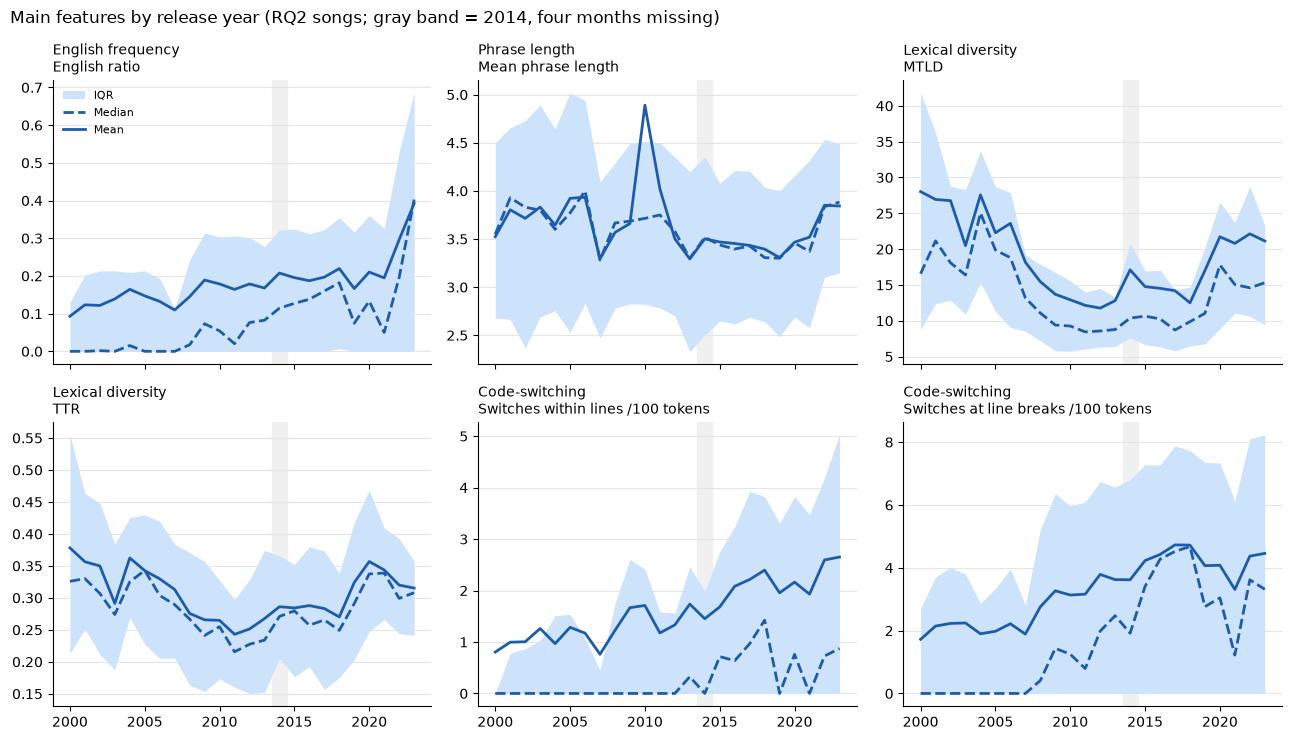

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True)
for ax, f in zip(axes.flat, MAIN_FEATURES):
    y = yearly[f]
    ax.fill_between(y.index, y["q1"], y["q3"], color="#cde2fb", linewidth=0, label="IQR")
    ax.plot(y.index, y["median"], color="#1c5cab", linewidth=2, linestyle="--", label="Median")
    ax.plot(y.index, y["mean"], color="#1c5cab", linewidth=2, label="Mean")
    ax.axvspan(2013.5, 2014.5, color="#f0f0f0", zorder=0)
    ax.set_title(f"{PERSPECTIVE_OF[f]}\n{LABELS[f]}", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
axes.flat[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Main features by release year (RQ2 songs; gray band = 2014, four months missing)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq2_trends_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.2 Trend Tests (Mann–Kendall, Sen's slope)

#### Procedure
- Mann–Kendall test on the 24 yearly means: is there a monotonic upward or downward trend?
- Sen's slope: median change per year (in the feature's own unit).
- The same test on yearly medians is shown for reference (`tau_median`, `p_median`).
- p-values Holm-corrected across the six features; `trend` is "increasing" or "decreasing" only if p_holm < .05.

In [15]:
def trend_row(data, feature, **kw):
    v = values(data, feature, **kw)
    by_year = v.groupby(data["release_year"])
    res_mean = mk.original_test(by_year.mean().dropna().values)
    res_median = mk.original_test(by_year.median().dropna().values)
    ok = v.notna()
    return {"perspective": PERSPECTIVE_OF[feature], "feature": feature,
            "tau": res_mean.Tau, "sen_slope_per_year": res_mean.slope, "p": res_mean.p,
            "tau_median": res_median.Tau, "p_median": res_median.p,
            "rho_song": stats.spearmanr(data.loc[ok, "release_year"], v[ok]).statistic,
            "p_rho_song": stats.spearmanr(data.loc[ok, "release_year"], v[ok]).pvalue}

def trend_table(data, **kw):
    t = pd.DataFrame([trend_row(data, f, **kw) for f in MAIN_FEATURES])
    t["p_holm"] = holm(t["p"]).values
    t["p_rho_song_holm"] = holm(t["p_rho_song"]).values
    t["trend"] = np.where(t["p_holm"] < .05,
                          np.where(t["sen_slope_per_year"] > 0, "increasing", "decreasing"), "no trend")
    return t

trend = trend_table(rq2)
display(trend[["perspective", "feature", "trend", "tau", "sen_slope_per_year", "p_holm",
               "tau_median", "p_median"]].round(4))

,perspective,feature,trend,tau,sen_slope_per_year,p_holm,tau_median,p_median
0,English frequency,en_ratio,increasing,0.6957,0.0056,0.0000,0.7210,0.0000
1,Phrase length,phrase_len_mean,no trend,-0.2174,-0.0137,0.2867,-0.2899,0.0500
2,Lexical diversity,mtld,no trend,-0.2754,-0.3144,0.1885,-0.2391,0.1069
3,Lexical diversity,ttr,no trend,-0.1667,-0.0016,0.2867,-0.0870,0.5683
4,Code-switching,cs_per100,increasing,0.7391,0.0723,0.0000,0.4203,0.0006
5,Code-switching,cs_inter_per100,increasing,0.6957,0.1345,0.0000,0.6667,0.0000


### 5.3 Song-Level Correlation

#### Procedure
Spearman correlation between release year and each feature across individual songs. This checks the yearly trend (5.2) without averaging songs into years.

In [16]:
display(trend[["perspective", "feature", "rho_song", "p_rho_song_holm"]].round(4))

,perspective,feature,rho_song,p_rho_song_holm
0,English frequency,en_ratio,0.1813,0.0000
1,Phrase length,phrase_len_mean,-0.0565,0.0004
2,Lexical diversity,mtld,-0.0708,0.0008
3,Lexical diversity,ttr,0.0112,0.5767
4,Code-switching,cs_per100,0.1892,0.0000
5,Code-switching,cs_inter_per100,0.2126,0.0000


### 5.4 Period Comparison (non-monotonic change)

#### Objective
The Mann–Kendall test (5.2) detects only steady increases or decreases. Lexical diversity appears to fall and then rise again (U-shape), so this section tests differences between release periods directly.

#### Procedure
- Kruskal–Wallis test across the five periods (2000–04 … 2020–23), with ε² and Holm correction.
- Dunn's test (Holm) with Cliff's δ for six key pairs: the four adjacent periods, plus 2000–04 vs. 2010–14 (fall) and 2010–14 vs. 2020–23 (rise).
- Run for all RQ2 songs and for songs by Korean artists only, to check whether foreign and English-only songs drive the early high values.

In [17]:
KEY_PAIRS = [("2000–04", "2005–09"), ("2005–09", "2010–14"), ("2010–14", "2015–19"), ("2015–19", "2020–23"),
             ("2000–04", "2010–14"), ("2010–14", "2020–23")]

def period_tests(data):
    data = data.copy()
    data["period"] = pd.cut(data["release_year"], bins=PERIOD_BINS, labels=PERIOD_LABELS)
    kw_rows, pair_rows = [], []
    for f in MAIN_FEATURES:
        v = values(data, f)
        d = pd.DataFrame({"v": v, "period": data["period"].astype(str)}).dropna()
        groups = [d.loc[d["period"] == p, "v"] for p in PERIOD_LABELS]
        H, p = stats.kruskal(*[g for g in groups if len(g) > 0])
        kw_rows.append({"perspective": PERSPECTIVE_OF[f], "feature": f, "n": len(d),
                        **{f"median_{p_}": g.median() for p_, g in zip(PERIOD_LABELS, groups)},
                        "H": H, "epsilon2": H / (len(d) - 1), "p": p})
        pmat = sp.posthoc_dunn(d, val_col="v", group_col="period", p_adjust="holm")
        for a, b in KEY_PAIRS:
            xa, xb = d.loc[d["period"] == a, "v"], d.loc[d["period"] == b, "v"]
            pair_rows.append({"feature": f, "pair": f"{a} vs {b}", "cliffs_delta": cliffs_delta(xb, xa),
                              "p_holm": pmat.loc[a, b] if a in pmat.index and b in pmat.columns else np.nan})
    kw_t = pd.DataFrame(kw_rows)
    kw_t["p_holm"] = holm(kw_t["p"]).values
    return kw_t, pd.DataFrame(pair_rows)

def show_period_tests(kw_t, pairs_t, title):
    print(title)
    display(kw_t[["perspective", "feature", "n"] + [f"median_{p}" for p in PERIOD_LABELS]
                 + ["H", "epsilon2", "p_holm"]].round(4))
    cell = pairs_t.apply(lambda r: f"{r['cliffs_delta']:+.2f}{'*' if r['p_holm'] < .05 else ''}", axis=1)
    print("Cliff's δ (later vs. earlier period; * p_holm < .05):")
    display(pairs_t.assign(cell=cell).pivot(index="feature", columns="pair", values="cell")
            .loc[MAIN_FEATURES, [f"{a} vs {b}" for a, b in KEY_PAIRS]])

period_kw, period_pairs = period_tests(rq2)
show_period_tests(period_kw, period_pairs, "All RQ2 songs")

All RQ2 songs


,perspective,feature,n,median_2000–04,median_2005–09,median_2010–14,median_2015–19,median_2020–23,H,epsilon2,p_holm
0,English frequency,en_ratio,7871,0.0000,0.0010,0.0617,0.1385,0.1412,238.6015,0.0303,0.0
1,Phrase length,phrase_len_mean,4610,3.7500,3.6667,3.5625,3.3917,3.6371,26.6618,0.0058,0.0
2,Lexical diversity,mtld,2479,19.9885,12.8026,9.0873,10.2039,15.3077,221.7873,0.0895,0.0
3,Lexical diversity,ttr,2479,0.3214,0.2787,0.2406,0.2663,0.3122,98.5854,0.0398,0.0
4,Code-switching,cs_per100,7871,0.0000,0.0000,0.0000,0.7752,0.6117,275.1132,0.0350,0.0
5,Code-switching,cs_inter_per100,7871,0.0000,0.0000,1.6216,4.0000,2.4597,362.5830,0.0461,0.0


Cliff's δ (later vs. earlier period; * p_holm < .05):


pair,2000–04 vs 2005–09,2005–09 vs 2010–14,2010–14 vs 2015–19,2015–19 vs 2020–23,2000–04 vs 2010–14,2010–14 vs 2020–23
feature,,,,,,
en_ratio,+0.02,+0.12*,+0.10*,+0.05,+0.14*,+0.13*
phrase_len_mean,-0.01,-0.05,-0.06,+0.12*,-0.06,+0.05
mtld,-0.28*,-0.24*,+0.07*,+0.33*,-0.50*,+0.39*
ttr,-0.15*,-0.15*,+0.10*,+0.22*,-0.31*,+0.33*
cs_per100,+0.05*,+0.08*,+0.15*,+0.00,+0.14*,+0.14*
cs_inter_per100,+0.04*,+0.14*,+0.15*,-0.07*,+0.18*,+0.07*


In [18]:
period_kw_kr, period_pairs_kr = period_tests(rq2_korean)
show_period_tests(period_kw_kr, period_pairs_kr, f"Korean artists only ({len(rq2_korean):,} songs)")

print("Songs with lexical diversity values (50+ English tokens) by period:")
n_lex = pd.DataFrame({
    "all RQ2": values(rq2, "mtld").notna().groupby(pd.cut(rq2["release_year"], PERIOD_BINS, labels=PERIOD_LABELS), observed=False).sum(),
    "Korean artists": values(rq2_korean, "mtld").notna().groupby(pd.cut(rq2_korean["release_year"], PERIOD_BINS, labels=PERIOD_LABELS), observed=False).sum(),
})
n_lex["removed (%)"] = ((1 - n_lex["Korean artists"] / n_lex["all RQ2"]) * 100).round(1)
display(n_lex)

Korean artists only (7,103 songs)


,perspective,feature,n,median_2000–04,median_2005–09,median_2010–14,median_2015–19,median_2020–23,H,epsilon2,p_holm
0,English frequency,en_ratio,7103,0.0000,0.0000,0.0616,0.1385,0.1538,262.2198,0.0369,0.0000
1,Phrase length,phrase_len_mean,4178,3.5738,3.5833,3.5143,3.3590,3.6216,15.8688,0.0038,0.0032
2,Lexical diversity,mtld,2219,17.8028,12.1563,8.6550,10.0446,15.0000,199.7488,0.0901,0.0000
3,Lexical diversity,ttr,2219,0.3211,0.2735,0.2317,0.2660,0.3112,93.7443,0.0423,0.0000
4,Code-switching,cs_per100,7103,0.0000,0.0000,0.0000,0.8499,0.7752,242.0056,0.0341,0.0000
5,Code-switching,cs_inter_per100,7103,0.0000,0.0000,2.0408,4.1026,3.3613,330.7778,0.0466,0.0000


Cliff's δ (later vs. earlier period; * p_holm < .05):


pair,2000–04 vs 2005–09,2005–09 vs 2010–14,2010–14 vs 2015–19,2015–19 vs 2020–23,2000–04 vs 2010–14,2010–14 vs 2020–23
feature,,,,,,
en_ratio,+0.05,+0.12*,+0.11*,+0.07,+0.17*,+0.15*
phrase_len_mean,+0.01,-0.03,-0.05,+0.11*,-0.02,+0.06
mtld,-0.28*,-0.25*,+0.11*,+0.32*,-0.50*,+0.43*
ttr,-0.15*,-0.15*,+0.12*,+0.22*,-0.30*,+0.35*
cs_per100,+0.06*,+0.08*,+0.14*,+0.03,+0.14*,+0.15*
cs_inter_per100,+0.05*,+0.14*,+0.14*,-0.04*,+0.20*,+0.08*


Songs with lexical diversity values (50+ English tokens) by period:


,all RQ2,Korean artists,removed (%)
release_year,,,
2000–04,217,174,19.8
2005–09,535,438,18.1
2010–14,792,721,9.0
2015–19,610,585,4.1
2020–23,325,301,7.4


## 6. Robustness Checks

### Objective
Check whether the main results change under reasonable alternative choices.

### 6.1 RQ1

#### Procedure
Repeat the Kruskal–Wallis test (3.1) under each condition. Each cell shows ε², followed by:
- `*` if p_holm < .05
- `≠` if the direction (sign of ρ) differs from the baseline

| Condition | What changes |
|---|---|
| baseline | — |
| alt_A / alt_B / alt_C | generation boundaries |
| nofill | fillers removed |
| high_conf | only songs with high-confidence debut years |
| min_en_30 / min_en_100 | minimum English tokens for TTR and MTLD (lexical diversity only) |

In [19]:
RQ1_CONDITIONS = {
    "baseline":   dict(gen_col="gen_baseline"),
    "alt_A":      dict(gen_col="gen_alt_A"),
    "alt_B":      dict(gen_col="gen_alt_B"),
    "alt_C":      dict(gen_col="gen_alt_C"),
    "nofill":     dict(gen_col="gen_baseline", version="nofill"),
    "high_conf":  dict(gen_col="gen_baseline", high_conf_only=True),
    "min_en_30":  dict(gen_col="gen_baseline", min_en=30, features=["mtld", "ttr"]),
    "min_en_100": dict(gen_col="gen_baseline", min_en=100, features=["mtld", "ttr"]),
}

rob1 = []
for name, cfg in RQ1_CONDITIONS.items():
    cfg = dict(cfg)
    data = rq1_songs(df, gen_col=cfg.pop("gen_col"), high_conf_only=cfg.pop("high_conf_only", False))
    features = cfg.pop("features", MAIN_FEATURES)
    t = kruskal_table(data, features=features, **cfg)
    t["condition"] = name
    rob1.append(t)
rob1 = pd.concat(rob1, ignore_index=True)

base_sign = rob1[rob1["condition"] == "baseline"].set_index("feature")["rho"].pipe(np.sign)
rob1["same_direction"] = np.sign(rob1["rho"]).values == base_sign.reindex(rob1["feature"]).values
rob1["cell"] = rob1.apply(lambda r: f"{r['epsilon2']:.3f}{'*' if r['p_holm'] < .05 else ''}"
                                    f"{'' if r['same_direction'] else ' ≠'}", axis=1)

display(rob1.pivot(index="feature", columns="condition", values="cell")
        .loc[MAIN_FEATURES, list(RQ1_CONDITIONS)].fillna("—"))

condition,baseline,alt_A,alt_B,alt_C,nofill,high_conf,min_en_30,min_en_100
feature,,,,,,,,
en_ratio,0.063*,0.068*,0.056*,0.064*,0.060*,0.069*,—,—
phrase_len_mean,0.001,0.001,0.001,0.001,0.001,0.002,—,—
mtld,0.041*,0.042*,0.043*,0.042*,0.034*,0.046*,0.032*,0.052*
ttr,0.013*,0.011*,0.016*,0.013*,0.011*,0.014*,0.011*,0.024* ≠
cs_per100,0.050*,0.058*,0.047*,0.049*,0.048*,0.054*,—,—
cs_inter_per100,0.059*,0.066*,0.050*,0.059*,0.057*,0.062*,—,—


### 6.2 RQ2

#### Procedure
Repeat the Mann–Kendall test (5.2) under each condition. Each cell shows Sen's slope per year, followed by `*` if p_holm < .05 and `≠` if the direction differs from the baseline.

| Condition | What changes |
|---|---|
| baseline | — |
| nofill | fillers removed |
| min_en_30 / min_en_100 | minimum English tokens for TTR and MTLD (lexical diversity only) |
| korean_only | songs by Korean artists only (foreign and unidentified artists removed) |

In [20]:
RQ2_CONDITIONS = {
    "baseline":    dict(),
    "nofill":      dict(version="nofill"),
    "min_en_30":   dict(min_en=30),
    "min_en_100":  dict(min_en=100),
    "korean_only": dict(korean_only=True),
}

rob2 = []
for name, cfg in RQ2_CONDITIONS.items():
    cfg = dict(cfg)
    data = rq2_korean if cfg.pop("korean_only", False) else rq2
    t = trend_table(data, **cfg)
    t["condition"] = name
    rob2.append(t)
rob2 = pd.concat(rob2, ignore_index=True)
# Thresholds only affect lexical diversity
rob2 = rob2[~(rob2["condition"].str.startswith("min_en") & ~rob2["feature"].isin(["mtld", "ttr"]))]

base_sign2 = rob2[rob2["condition"] == "baseline"].set_index("feature")["sen_slope_per_year"].pipe(np.sign)
rob2["same_direction"] = np.sign(rob2["sen_slope_per_year"]).values == base_sign2.reindex(rob2["feature"]).values
rob2["cell"] = rob2.apply(lambda r: f"{r['sen_slope_per_year']:+.4f}{'*' if r['p_holm'] < .05 else ''}"
                                    f"{'' if r['same_direction'] else ' ≠'}", axis=1)

display(rob2.pivot(index="feature", columns="condition", values="cell")
        .loc[MAIN_FEATURES, list(RQ2_CONDITIONS)].fillna("—"))

condition,baseline,nofill,min_en_30,min_en_100,korean_only
feature,,,,,
en_ratio,+0.0056*,+0.0047*,—,—,+0.0063*
phrase_len_mean,-0.0137,-0.0106,—,—,-0.0047
mtld,-0.3144,-0.3181,-0.2521,-0.3548,-0.2728
ttr,-0.0016,-0.0013,-0.0011,-0.0003,-0.0015
cs_per100,+0.0723*,+0.0642*,—,—,+0.0732*
cs_inter_per100,+0.1345*,+0.1330*,—,—,+0.1410*


## 7. Summary and Export

### Objective
One table that answers RQ1 and RQ2 for each of the four perspectives, and export all tables and figures for the report.

- **RQ1 robust:** number of RQ1 conditions (6.1) in which the difference is significant with the same direction as the baseline.
- **RQ2 robust:** the same for RQ2 conditions (6.2).
- **RQ2 period difference:** ε² of the period comparison (5.4) for all RQ2 songs and Korean artists only; `*` if p_holm < .05. Captures non-monotonic change that the trend test misses.

In [21]:
r1 = rob1.assign(ok=(rob1["p_holm"] < .05) & rob1["same_direction"]).groupby("feature")["ok"].agg(["sum", "size"])
r2 = rob2.assign(ok=(rob2["p_holm"] < .05) & rob2["same_direction"]).groupby("feature")["ok"].agg(["sum", "size"])

summary = pd.DataFrame({
    "Perspective": kw_all["perspective"].values,
    "Feature": [LABELS[f] for f in MAIN_FEATURES],
    "RQ1 median 1st → 4th": [" → ".join(f"{kw_all.loc[i, f'median_{g}']:.3g}" for g in GENS) for i in kw_all.index],
    "RQ1 ε² (all)": kw_all["epsilon2"].round(3).values,
    "RQ1 ρ (direction)": kw_all["rho"].round(3).values,
    "RQ1 significant (all / within / adjusted)": [
        f"{sig(a)} / {sig(b)} / {sig(c)}"
        for a, b, c in zip(kw_all["p_holm"], kw_within["p_holm"], reg["p_gen_joint_holm"])],
    "RQ1 robust": [f"{r1.loc[f, 'sum']}/{r1.loc[f, 'size']}" for f in MAIN_FEATURES],
    "RQ2 trend": trend["trend"].values,
    "RQ2 Sen's slope / year": trend["sen_slope_per_year"].round(4).values,
    "RQ2 significant": trend["p_holm"].map(sig).values,
    "RQ2 robust": [f"{r2.loc[f, 'sum']}/{r2.loc[f, 'size']}" for f in MAIN_FEATURES],
    "RQ2 period difference ε² (all / Korean)": [
        f"{a:.3f}{'*' if pa < .05 else ''} / {b:.3f}{'*' if pb < .05 else ''}"
        for a, pa, b, pb in zip(period_kw["epsilon2"], period_kw["p_holm"],
                                period_kw_kr["epsilon2"], period_kw_kr["p_holm"])],
})
display(summary)

,Perspective,Feature,RQ1 median 1st → 4th,RQ1 ε² (all),RQ1 ρ (direction),RQ1 significant (all / within / adjusted),RQ1 robust,RQ2 trend,RQ2 Sen's slope / year,RQ2 significant,RQ2 robust,RQ2 period difference ε² (all / Korean)
0,English frequency,English ratio,0 → 0.0695 → 0.181 → 0.471,0.063,0.233,yes / yes / yes,6/6,increasing,0.0056,yes,3/3,0.030* / 0.037*
1,Phrase length,Mean phrase length,3.59 → 3.58 → 3.42 → 3.56,0.001,-0.011,no / no / no,0/6,no trend,-0.0137,no,0/3,0.006* / 0.004*
2,Lexical diversity,MTLD,14.4 → 9.5 → 10.6 → 12.9,0.041,-0.080,yes / no / yes,8/8,no trend,-0.3144,no,0/5,0.090* / 0.090*
3,Lexical diversity,TTR,0.293 → 0.256 → 0.272 → 0.308,0.013,-0.024,yes / no / yes,7/8,no trend,-0.0016,no,0/5,0.040* / 0.042*
4,Code-switching,Switches within lines /100 tokens,0 → 0 → 0.973 → 3.67,0.050,0.208,yes / yes / yes,6/6,increasing,0.0723,yes,3/3,0.035* / 0.034*
5,Code-switching,Switches at line breaks /100 tokens,0 → 2.21 → 4.67 → 7.5,0.059,0.235,yes / yes / yes,6/6,increasing,0.1345,yes,3/3,0.046* / 0.047*


In [22]:
exports = {
    "descriptives_by_generation": desc_gen,
    "descriptives_by_period": desc_period,
    "rq1_kruskal_all": kw_all,
    "rq1_dunn_all": dunn_all,
    "rq1_median_ci": median_ci,
    "rq1_kruskal_within_2015_2023": kw_within,
    "rq1_dunn_within_2015_2023": dunn_within,
    "rq1_regression": reg,
    "rq1_comparison": compare,
    "rq2_yearly_mean": pd.DataFrame({f: yearly[f]["mean"] for f in MAIN_FEATURES}),
    "rq2_trend": trend,
    "rq2_period_kruskal": period_kw,
    "rq2_period_pairs": period_pairs,
    "rq2_period_kruskal_korean": period_kw_kr,
    "rq2_period_pairs_korean": period_pairs_kr,
    "robustness_rq1": rob1.drop(columns="cell"),
    "robustness_rq2": rob2.drop(columns="cell"),
    "summary": summary,
}
for name, table in exports.items():
    table.to_csv(TABLE_DIR / f"{name}.csv", index=name == "rq2_yearly_mean", encoding="utf-8-sig")

print(f"Saved {len(exports)} tables to {TABLE_DIR}")
print(f"Saved figures to {FIG_DIR}: {', '.join(p.name for p in sorted(FIG_DIR.glob('*.png')))}")

Saved 18 tables to ../results/tables
Saved figures to ../results/figures: rq1_boxplots_by_generation.png, rq2_trends_by_year.png
